In [1]:
import numpy as np
import matplotlib.pyplot as plt


<H1>Gaussian Elimination</h1>

<h1>4.2</h1>

In [2]:
A = np.array([[1, 3, 5, 7],
              [2, 4, 6, 8],
              [-3, -2, -1, 0]])
u = np.array([10, 20, 30])

print("A =\n", A)
print("u =", u)
print("shape of A:", A.shape)
print("shape of u:", u.shape)
print("first column of A:", A[:, 0])
print("first two rows of A:\n", A[:2, :])
print("first two entries of u:", u[:2])
print("last two entries of u:", u[-2:])
print("bottom-left 2x2 block:\n", A[1:, :-2])
print("middle 2 entries of the middle row:", A[1, 1:-1])


A =
 [[ 1  3  5  7]
 [ 2  4  6  8]
 [-3 -2 -1  0]]
u = [10 20 30]
shape of A: (3, 4)
shape of u: (3,)
first column of A: [ 1  2 -3]
first two rows of A:
 [[1 3 5 7]
 [2 4 6 8]]
first two entries of u: [10 20]
last two entries of u: [20 30]
bottom-left 2x2 block:
 [[ 2  4]
 [-3 -2]]
middle 2 entries of the middle row: [4 6]


<h1>4.5</h1>

In [3]:
def myDotProduct(u,v):
    return u@v

<h1>4.6</h1>

In [4]:
u = np.array([1,2,3])
v = np.array([4,5,6])
myDotProduct(u,v)

np.int64(32)

<h1>4.8</h1>

In [5]:
np.dot(u, v)

np.int64(32)

<h1>4.11</h1>

In [6]:
def myMatrixMult(A, B):
    """Matrix product computed row by row with NumPy dot products."""
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    if A.shape[1] != B.shape[0]:
        raise ValueError(f"incompatible shapes: {A.shape} and {B.shape}")
    result = np.zeros((A.shape[0], B.shape[1]))
    for i in range(A.shape[0]):
        result[i, :] = A[i, :] @ B
    return result


In [7]:
A = np.array([[1, 2], [3, 4], [5, 6]], dtype=float)
B = np.array([[7, 8, 9], [10, 11, 12]], dtype=float)

print("myMatrixMult(A, B):\n", myMatrixMult(A, B))
print("A @ B:\n", A @ B)
assert np.allclose(myMatrixMult(A, B), A @ B)


myMatrixMult(A, B):
 [[ 27.  30.  33.]
 [ 61.  68.  75.]
 [ 95. 106. 117.]]
A @ B:
 [[ 27.  30.  33.]
 [ 61.  68.  75.]
 [ 95. 106. 117.]]


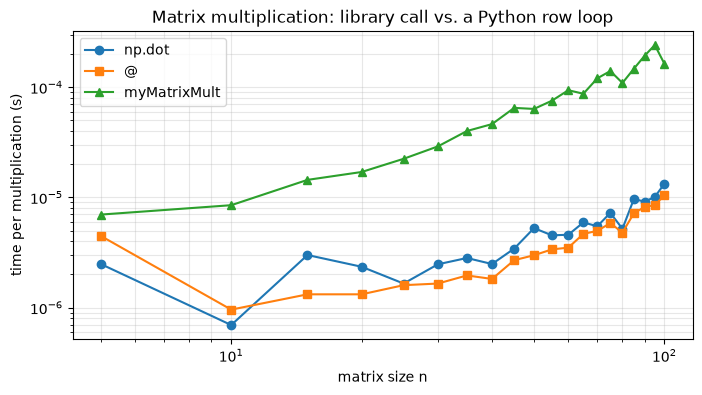

In [8]:
import time

rng = np.random.default_rng(2024)

def average_time(func, A, B, repeats=3):
    start = time.perf_counter()
    for _ in range(repeats):
        func(A, B)
    return (time.perf_counter() - start) / repeats

sizes = np.arange(5, 101, 5)
dot_times, at_times, manual_times = [], [], []
for n in sizes:
    A = rng.random((n, n))
    B = rng.random((n, n))
    dot_times.append(average_time(np.dot, A, B))
    at_times.append(average_time(lambda x, y: x @ y, A, B))
    manual_times.append(average_time(myMatrixMult, A, B))

plt.figure(figsize=(8, 4))
plt.loglog(sizes, dot_times, "o-", label="np.dot")
plt.loglog(sizes, at_times, "s-", label="@")
plt.loglog(sizes, manual_times, "^-", label="myMatrixMult")
plt.xlabel("matrix size n")
plt.ylabel("time per multiplication (s)")
plt.title("Matrix multiplication: library call vs. a Python row loop")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()
